# Recurrent PPO with LSTM: main experiment

Individual ECE556 project by Taimoor Shahzad. This is the primary notebook: seed 25, a 25-day observation window, and ten training rounds. Its saved outputs match the supplied checkpoint and the final report.

**Viewing does not require execution.** Outputs are retained from the original experiment. Packaging changed setup and file paths only; no training or evaluation was rerun. See [experiment notes](../docs/experiment_notes.md) for limitations and report/code differences.

For optional execution, install `requirements.txt` first. Run the setup and data cells, then the environment/function definitions. The same cell also contains the long training loop; do not run that loop merely to view results or load the included checkpoint. Newly trained models are saved under `models/runs/seed_runs/`, separately from the included checkpoint.


In [ ]:
# === STEP 1: DOWNLOAD AND NORMALIZE RETURNS ===
import yfinance as yf
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from collections import deque
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.utils import set_random_seed
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.logger import configure
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor
from stable_baselines3.common.logger import TensorBoardOutputFormat
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.base_class import BaseAlgorithm
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.callbacks import StopTrainingOnNoModelImprovement
from stable_baselines3.common.callbacks import CallbackList
from stable_baselines3.common.vec_env import VecMonitor
from stable_baselines3.common.vec_env import VecNormalize
from stable_baselines3.common.logger import configure
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt
from stable_baselines3.common.env_util import make_vec_env
from sb3_contrib.ppo_recurrent import RecurrentPPO

from pathlib import Path

# Find the repository from either its root or a notebook subfolder.
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models").is_dir() and (p / "notebooks").is_dir()),
    Path.cwd(),
)


In [ ]:
# === STEP 1: DOWNLOAD AND NORMALIZE RETURNS ===
tickers = ['AAPL', 'MSFT', 'TSLA', 'AMZN', 'GOOG']
data = yf.download(tickers, start='2015-01-01', end='2025-06-30', auto_adjust=True)['Close'].dropna()
returns = np.log(data / data.shift(1)).dropna()
returns.columns = [f"Asset_{i+1}" for i in range(len(returns.columns))]
unnormalized_returns = returns.copy()

scaler = StandardScaler()
scaled_returns = pd.DataFrame(scaler.fit_transform(returns), index=returns.index, columns=returns.columns)

# === STEP 2: SPLIT INTO DATASETS ===
train_returns = scaled_returns.loc["2015-01-01":"2020-12-31"].copy()
val_returns = scaled_returns.loc["2021-01-01":"2023-12-31"].copy()
test_returns = scaled_returns.loc["2024-01-01":"2025-06-30"].copy()

[*********************100%***********************]  5 of 5 completed



🚀 Training with seed 25
Training round 1
Validation Sharpe Ratio: 0.8645


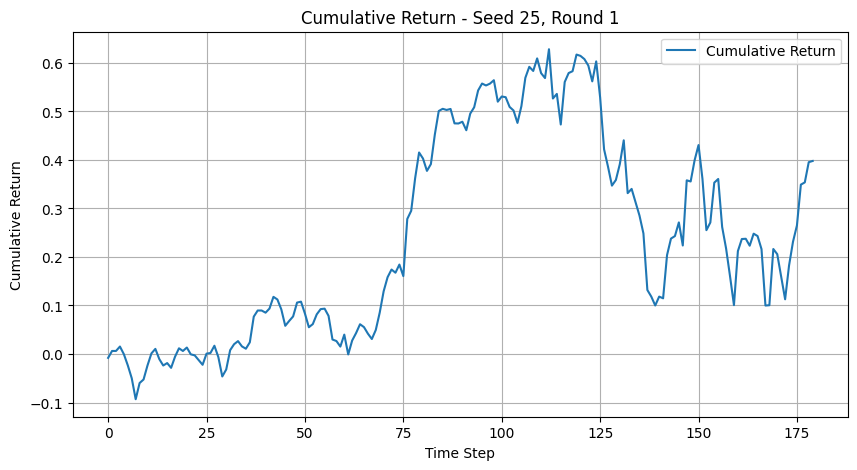

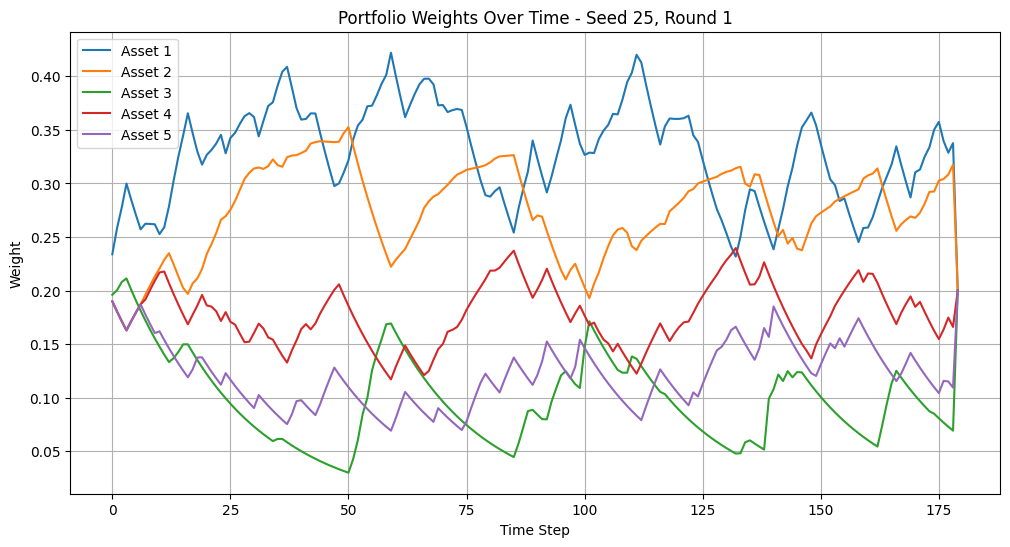

Training round 2
Validation Sharpe Ratio: 0.8162


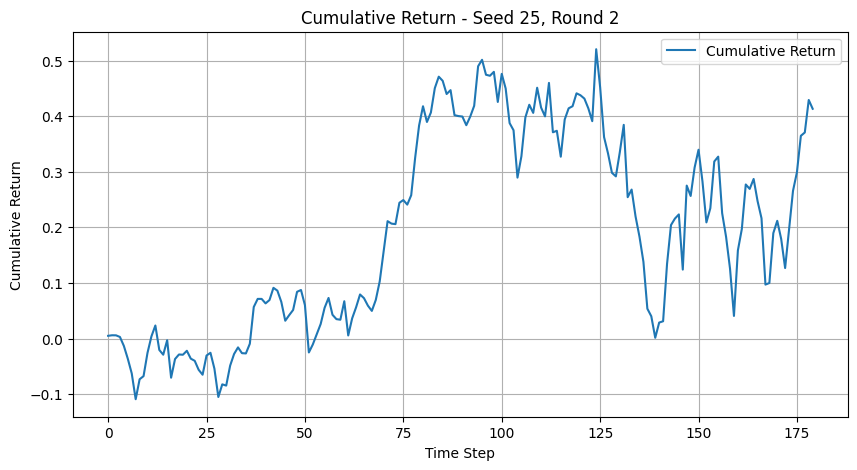

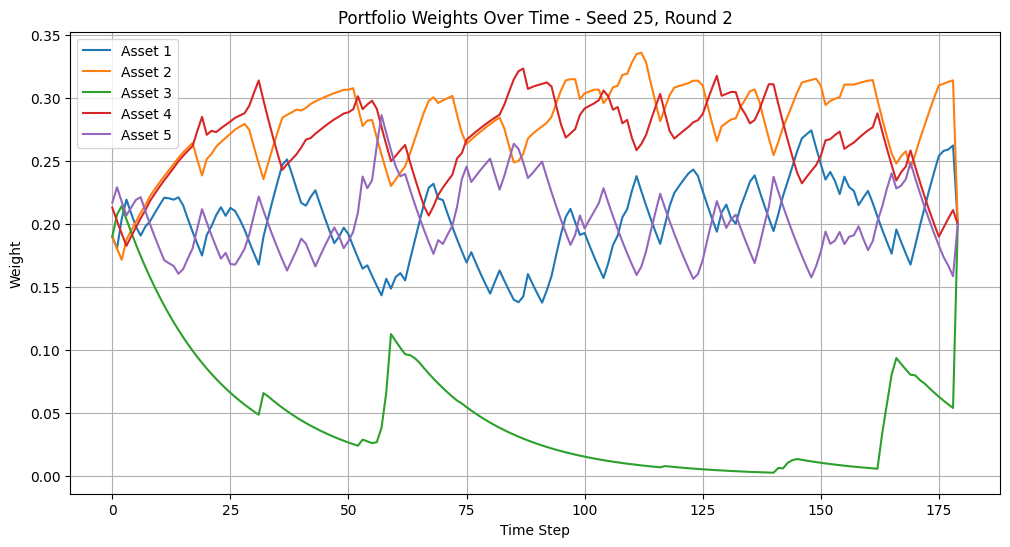

Training round 3
Validation Sharpe Ratio: 0.7462


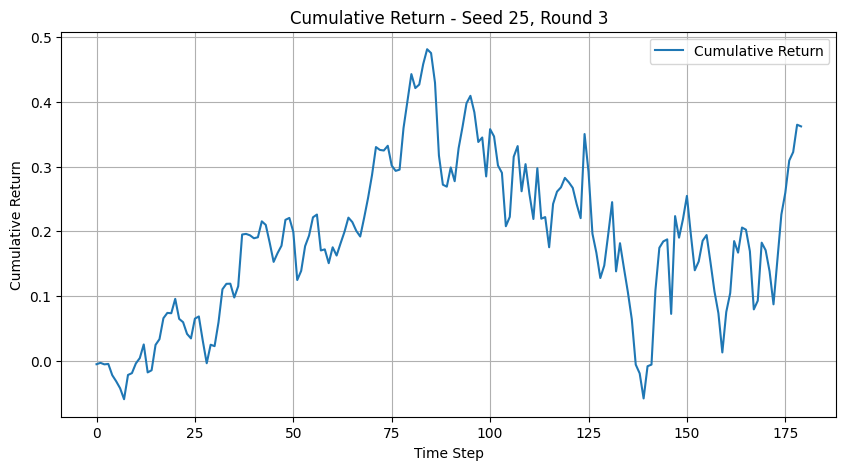

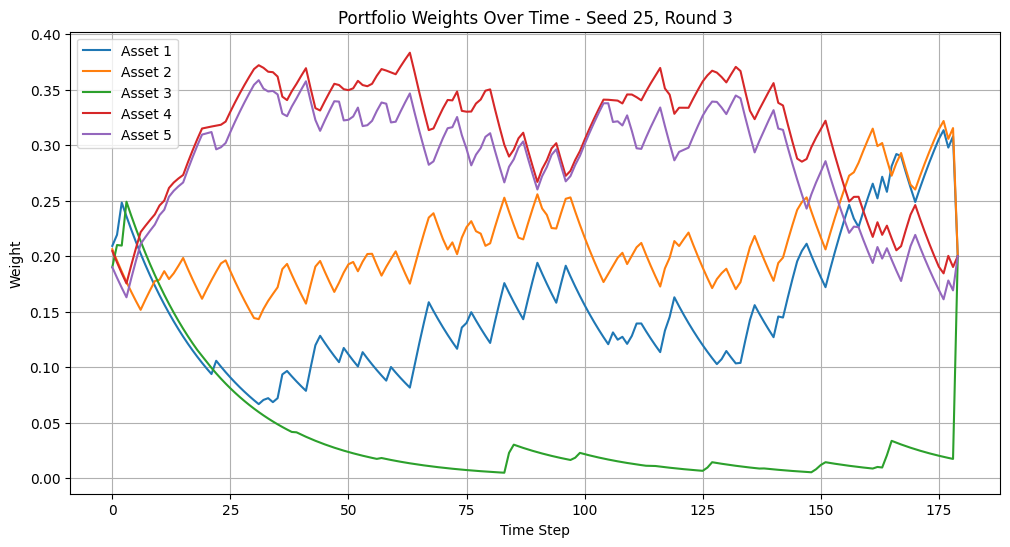

Training round 4
Validation Sharpe Ratio: 1.2315


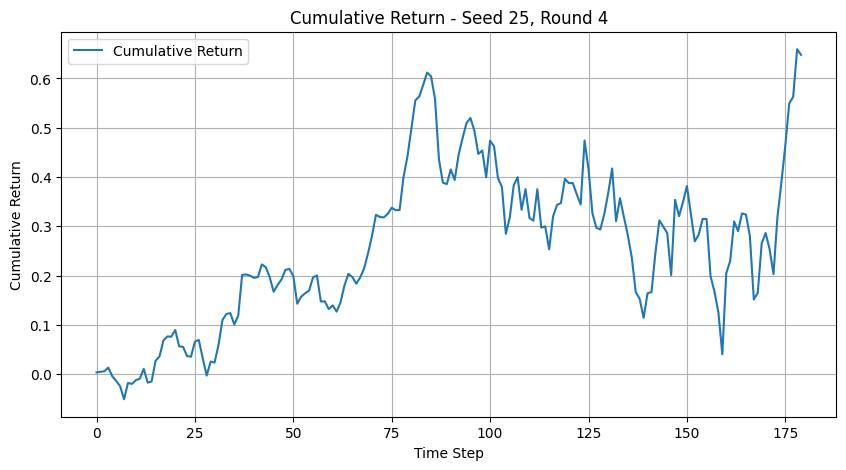

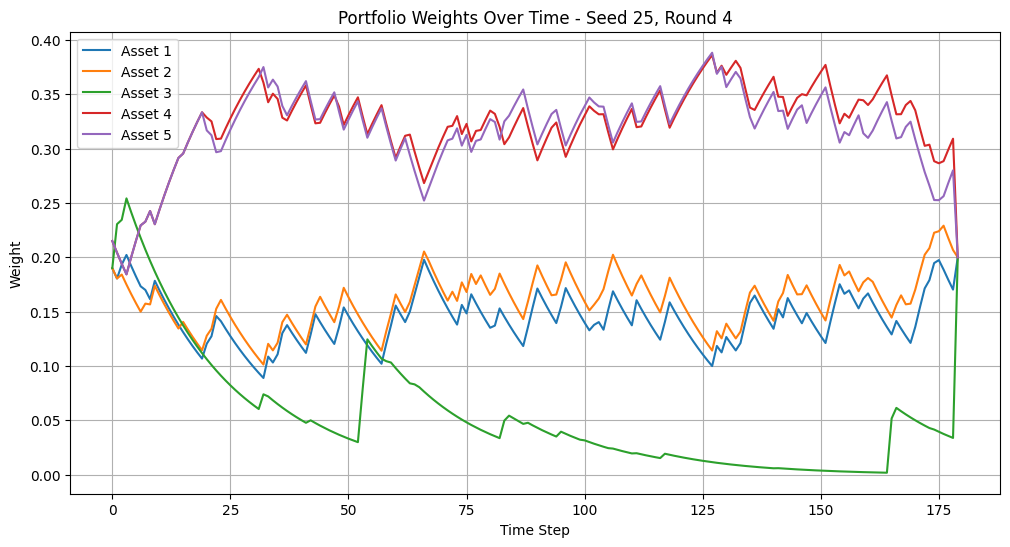

Training round 5
Validation Sharpe Ratio: 1.1302


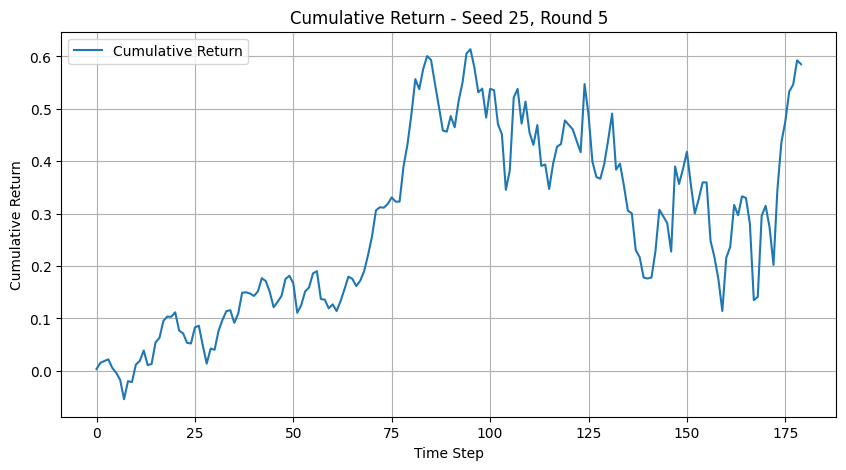

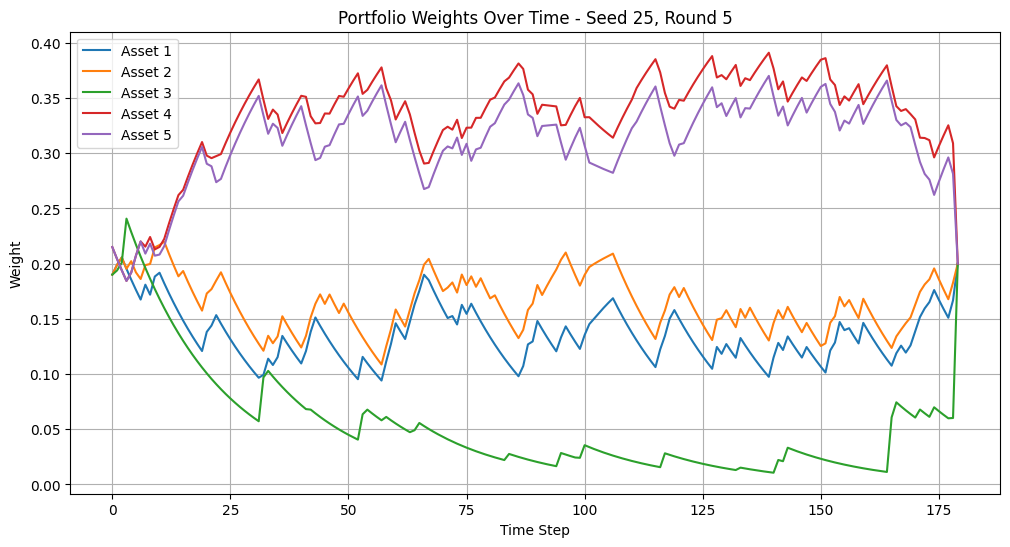

Training round 6
Validation Sharpe Ratio: 1.2267


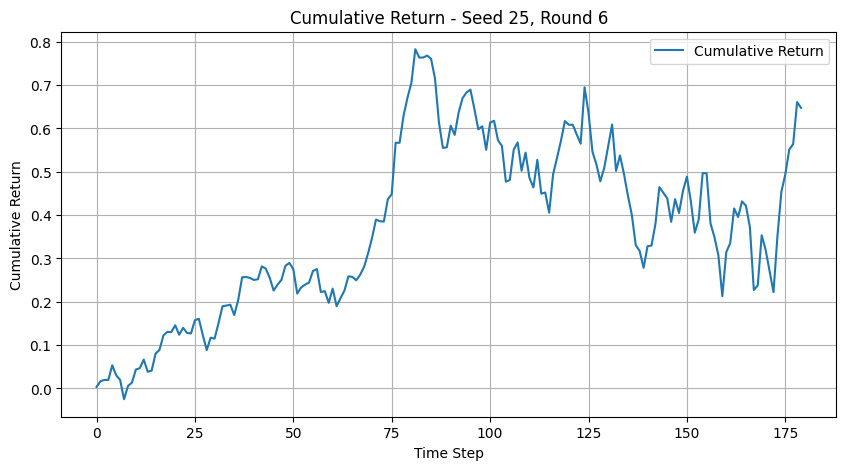

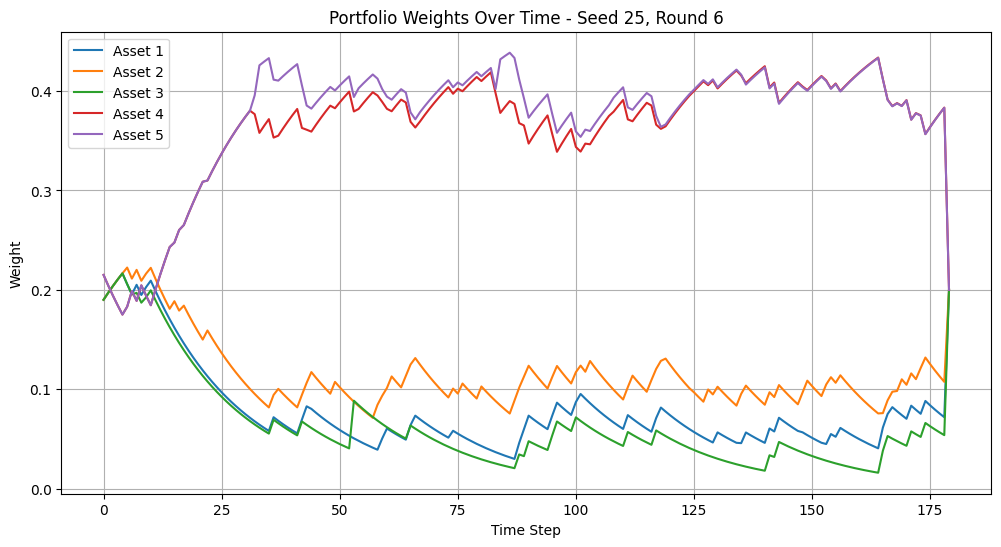

Training round 7
Validation Sharpe Ratio: 1.4035


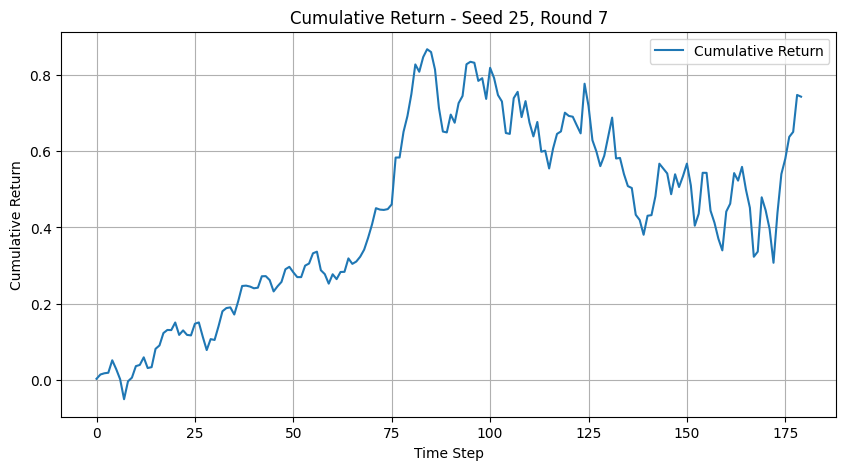

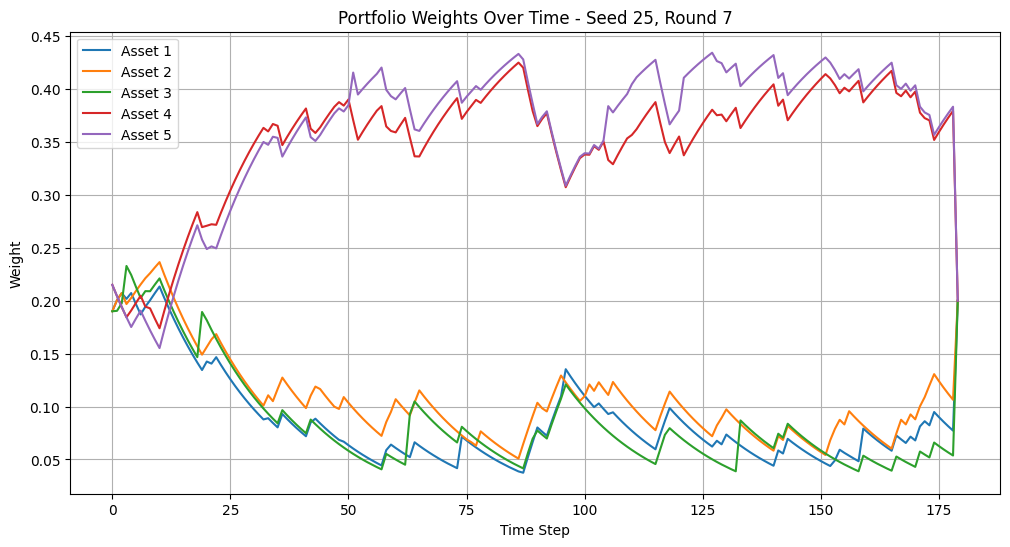

Training round 8
Validation Sharpe Ratio: 1.6340


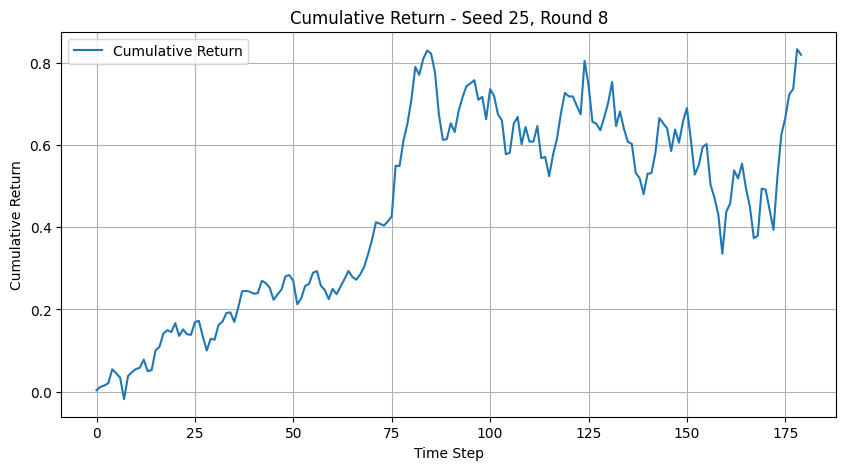

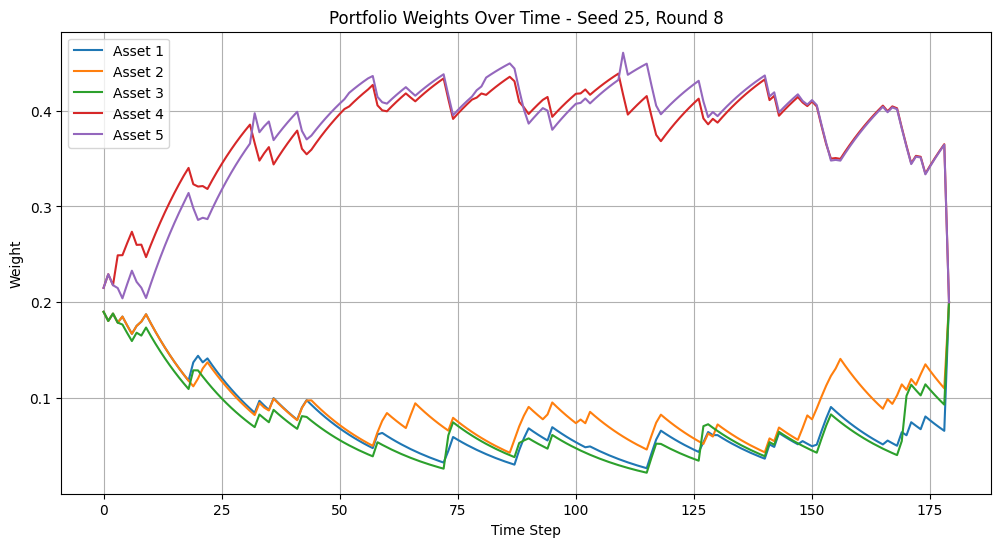

Training round 9
Validation Sharpe Ratio: 1.3126


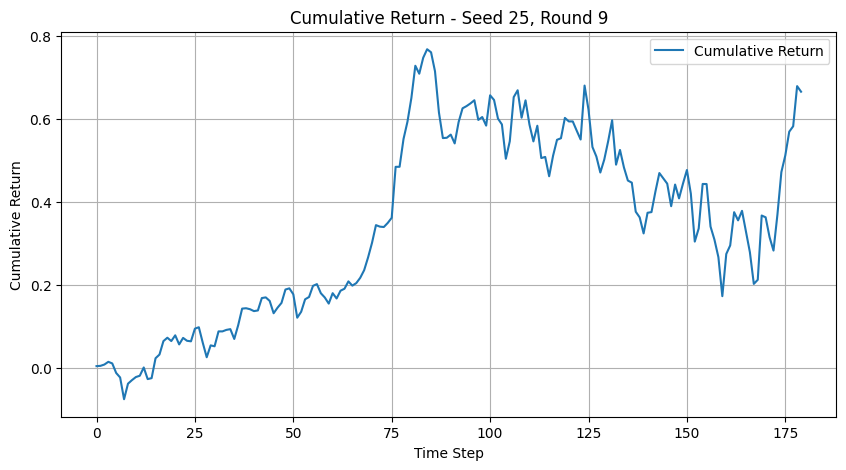

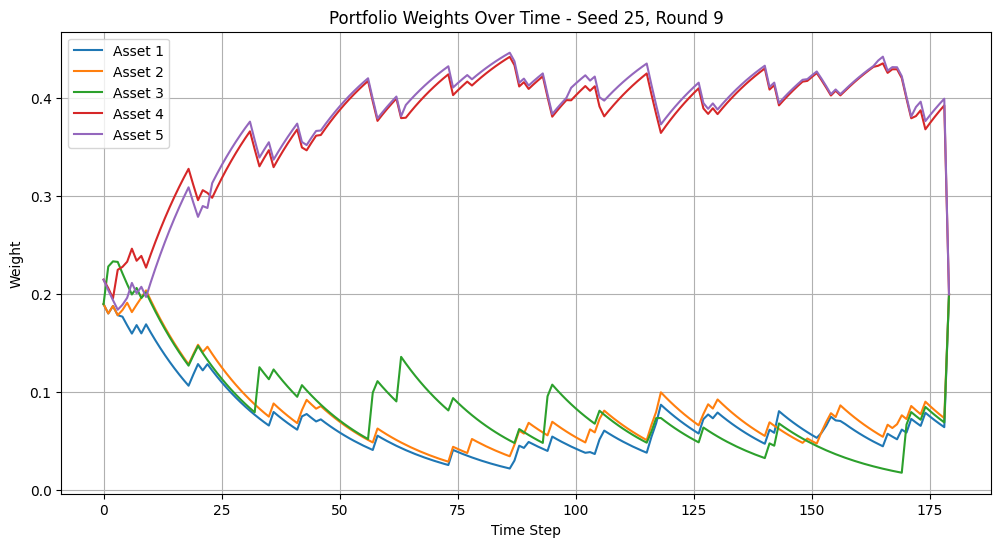

Training round 10
Validation Sharpe Ratio: 1.7522


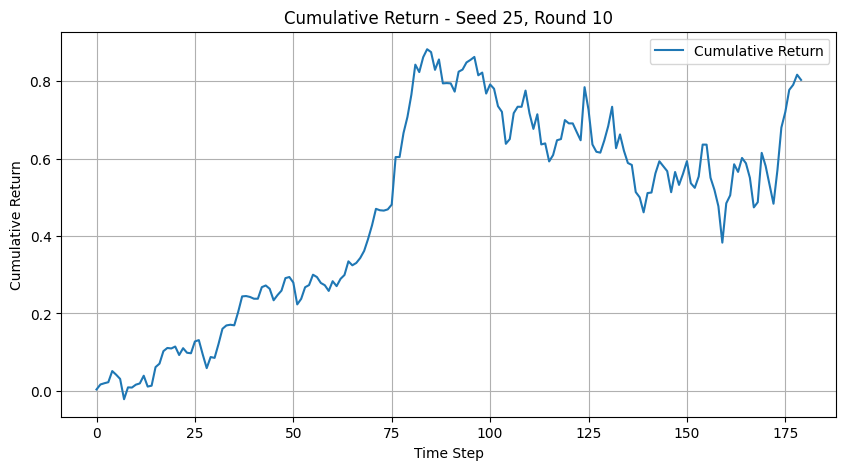

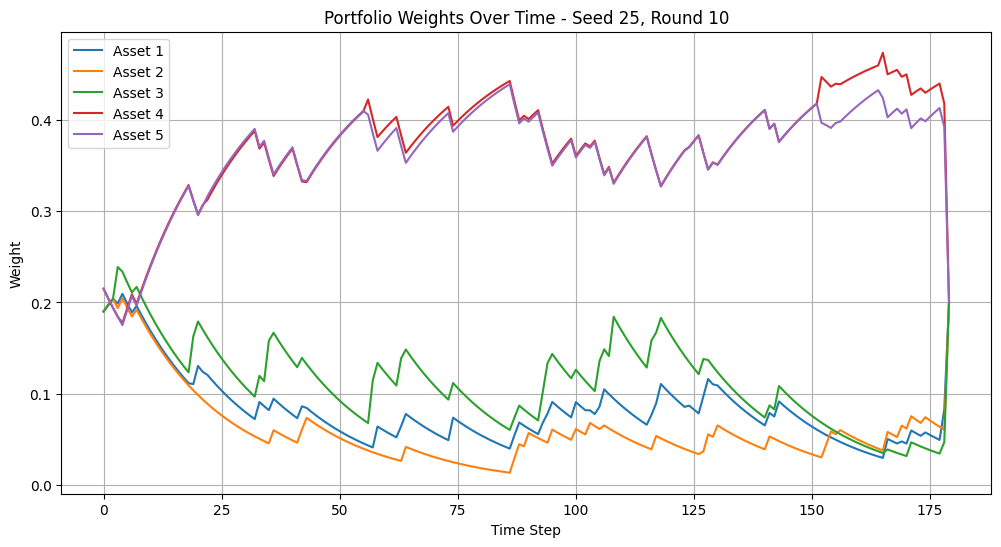

✅ Best Sharpe for seed 25: 1.7522

=== Summary ===
🥇 Best seed: 25 with Sharpe: 1.7522
📁 Best model saved at: models/runs/seed_runs/ppo_best_model_seed25_round10.zip


In [ ]:
import gymnasium as gym
from gymnasium import spaces
import os
import random
import torch
# === Environment ===
class PortfolioEnv(gym.Env):
    def __init__(self, data, window_size=25, episode_length=180, sharpe_window=50,
                 transaction_cost_rate=0.001, reward_blend=(0.90, 0.10)):
        super().__init__()
        self.data = data.values
        self.window_size = window_size
        self.episode_length = episode_length
        self.sharpe_window = sharpe_window
        self.transaction_cost_rate = transaction_cost_rate
        self.n_assets = self.data.shape[1]

        self.initial_blend = reward_blend
        self.final_blend = (0.80, 0.20)

        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(self.n_assets * self.window_size,),
            dtype=np.float32
        )
        self.action_space = spaces.Box(low=0, high=1, shape=(self.n_assets,), dtype=np.float32)
        self.returns_buffer = deque(maxlen=self.sharpe_window)
        self.seed()
        self.reset()

    def seed(self, seed=42):
        self.np_random = np.random.RandomState(seed)
        self._seed_value = seed

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.seed(seed)
        elif not hasattr(self, "_seed_value"):
            self.seed(42)

        max_start = len(self.data) - self.episode_length - 1
        if max_start <= self.window_size:
            raise ValueError("Episode length too long for data size.")

        self.start_step = self.np_random.randint(self.window_size, max_start)
        self.current_step = self.start_step
        self.weights = np.ones(self.n_assets) / self.n_assets
        self.returns_buffer.clear()
        return self._get_observation(), {}

    def _get_observation(self):
        window = self.data[self.current_step - self.window_size + 1: self.current_step + 1]
        obs = window.flatten().astype(np.float32)
        return obs

    def step(self, action):
        action = action / (np.sum(action) + 1e-8)
        r_t = self.data[self.current_step + 1]
        portfolio_return = np.dot(action, r_t)
        portfolio_return = np.clip(portfolio_return, -0.999, None)

        turnover = np.sum(np.abs(action - self.weights))
        transaction_cost = self.transaction_cost_rate * turnover
        allocation_change_penalty = np.sum((action - self.weights) ** 2)
        penalty_weight = 0.1

        self.returns_buffer.append(portfolio_return)
        if len(self.returns_buffer) >= self.sharpe_window:
            mean_r = np.mean(self.returns_buffer)
            std_r = np.std(self.returns_buffer) + 1e-8
            sharpe_reward = mean_r / std_r
        else:
            sharpe_reward = 0.0

        progress = (self.current_step - self.start_step) / self.episode_length
        dynamic_blend_0 = self.initial_blend[0] + progress * (self.final_blend[0] - self.initial_blend[0])
        dynamic_blend_1 = self.initial_blend[1] + progress * (self.final_blend[1] - self.initial_blend[1])

        reward = dynamic_blend_0 * sharpe_reward + dynamic_blend_1 * portfolio_return
        reward -= transaction_cost
        reward -= penalty_weight * allocation_change_penalty

        self.current_step += 1
        done = (self.current_step - self.start_step) >= self.episode_length
        self.weights = 0.95 * self.weights + 0.05 * action

        return self._get_observation(), reward, done, False, {"actual_return": portfolio_return}


# === Validation Function ===
def sharpe_ratio(returns):
    excess = np.array(returns)
    return np.mean(excess) / (np.std(excess) + 1e-8) * np.sqrt(252)


def evaluate_model_on_validation(model, val_env, unnormalized_val_returns, seed=42):
    val_env.seed(seed)
    obs = val_env.reset()
    set_random_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

    lstm_states = None
    episode_starts = np.ones((val_env.num_envs,), dtype=bool)
    done = False
    val_returns = []
    weights_over_time = []
    step = val_env.envs[0].current_step

    while not done:
        action, lstm_states = model.predict(obs, state=lstm_states, episode_start=episode_starts, deterministic=True)
        obs, reward, done, info = val_env.step(action)
        episode_starts = np.array([done[0]])

        if step + 1 >= len(unnormalized_val_returns):
            break

        actual_ret = unnormalized_val_returns.iloc[step + 1].values
        portfolio_ret = np.dot(action[0], actual_ret)
        simple_ret = np.exp(portfolio_ret) - 1
        val_returns.append(simple_ret)

        weights_over_time.append(val_env.envs[0].weights.copy())
        step += 1

    return sharpe_ratio(val_returns), val_returns, weights_over_time


# === Training Loop ===
log_dir = str(REPO_ROOT / "ppo_tensorboard")
os.makedirs(log_dir, exist_ok=True)
writer = SummaryWriter(log_dir=log_dir)

model_save_base_path = str(REPO_ROOT / "models" / "runs" / "seed_runs")
os.makedirs(model_save_base_path, exist_ok=True)

seeds = [25]
overall_best_sharpe = -float("inf")
overall_best_seed = None
overall_best_model_path = None

for seed in seeds:
    print(f"\n🚀 Training with seed {seed}")
    train_env = DummyVecEnv([lambda: PortfolioEnv(train_returns)])
    val_env = DummyVecEnv([lambda: PortfolioEnv(val_returns)])

    set_random_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

    model = RecurrentPPO(
        "MlpLstmPolicy",
        train_env,
        verbose=0,
        n_steps=128,
        learning_rate=0.0001,
        ent_coef=0.01,
        batch_size=64,
        tensorboard_log=None,
        seed=seed
    )

    best_model = None
    best_sharpe = -float("inf")
    no_improve_counter = 0
    patience = 4
    train_steps_per_round = 50000  # Temporary for testing
    max_rounds = 10

    for round in range(max_rounds):
        print(f"Training round {round + 1}")
        model.learn(total_timesteps=train_steps_per_round, reset_num_timesteps=False)

        val_sharpe, val_returns_list, val_weights = evaluate_model_on_validation(
            model, val_env, unnormalized_returns.loc["2021-01-01":"2023-12-31"]
        )
        print(f"Validation Sharpe Ratio: {val_sharpe:.4f}")

        writer.add_scalar("val/Sharpe_Ratio", val_sharpe, round)
        writer.add_scalar("val/Cumulative_Return", np.sum(val_returns_list), round)

        val_weights = np.array(val_weights)
        mean_weights = np.mean(val_weights, axis=0)
        for i, w in enumerate(mean_weights):
            writer.add_scalar(f"val/Avg_Weight_Asset_{i+1}", w, round)
        plt.figure(figsize=(10, 5))
        cumulative_returns = np.cumsum(val_returns_list)
        plt.plot(cumulative_returns, label="Cumulative Return")
        plt.xlabel("Time Step")
        plt.ylabel("Cumulative Return")
        plt.title(f"Cumulative Return - Seed {seed}, Round {round + 1}")
        plt.grid(True)
        plt.legend()
        plt.show()

        plt.figure(figsize=(12, 6))
        for i in range(val_weights.shape[1]):
            plt.plot(val_weights[:, i], label=f'Asset {i+1}')
        plt.xlabel("Time Step")
        plt.ylabel("Weight")
        plt.title(f"Portfolio Weights Over Time - Seed {seed}, Round {round + 1}")
        plt.legend()
        plt.grid(True)
        plt.show()

        if val_sharpe > best_sharpe + 1e-4:
            best_sharpe = val_sharpe
            model_path = f"{model_save_base_path}/ppo_best_model_seed{seed}_round{round+1}.zip"
            model.save(model_path)
            best_model = RecurrentPPO.load(model_path, env=train_env)
            no_improve_counter = 0
        else:
            no_improve_counter += 1

        if no_improve_counter >= patience:
            print("Early stopping triggered.")
            break

    print(f"✅ Best Sharpe for seed {seed}: {best_sharpe:.4f}")
    if best_sharpe > overall_best_sharpe:
        overall_best_sharpe = best_sharpe
        overall_best_seed = seed
        overall_best_model_path = model_path

print("\n=== Summary ===")
print(f"🥇 Best seed: {overall_best_seed} with Sharpe: {overall_best_sharpe:.4f}")
print(f"📁 Best model saved at: {overall_best_model_path}")
writer.close()


In [ ]:
def evaluate_model_on_test(model_path, test_returns, unnormalized_test_returns, seed=25):
    test_env = DummyVecEnv([lambda: PortfolioEnv(test_returns)])

    # Load saved model
    model = RecurrentPPO.load(model_path, env=test_env)

    # Set all seeds
    set_random_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)

    obs = test_env.reset()
    lstm_states = None
    episode_starts = np.ones((test_env.num_envs,), dtype=bool)
    done = False
    test_returns_list = []
    weights_over_time = []
    step = test_env.envs[0].current_step

    while not done:
        action, lstm_states = model.predict(obs, state=lstm_states, episode_start=episode_starts, deterministic=True)
        obs, reward, done, info = test_env.step(action)
        episode_starts = np.array([done[0]])

        if step + 1 >= len(unnormalized_test_returns):
            break

        actual_ret = unnormalized_test_returns.iloc[step + 1].values
        portfolio_ret = np.dot(action[0], actual_ret)
        simple_ret = np.exp(portfolio_ret) - 1
        test_returns_list.append(simple_ret)

        weights_over_time.append(test_env.envs[0].weights.copy())
        step += 1

    return test_returns_list, np.array(weights_over_time)


In [ ]:
def plot_test_performance(returns_list, weights_array, seed_label="Final"):
    plt.figure(figsize=(10, 5))
    cumulative_returns = np.cumsum(returns_list)
    plt.plot(cumulative_returns, label="Cumulative Return")
    plt.xlabel("Time Step")
    plt.ylabel("Cumulative Return")
    plt.title(f"Test Set Cumulative Return - {seed_label}")
    plt.grid(True)
    plt.legend()
    plt.show()

    plt.figure(figsize=(12, 6))
    for i in range(weights_array.shape[1]):
        plt.plot(weights_array[:, i], label=f'Asset {i+1}')
    plt.xlabel("Time Step")
    plt.ylabel("Weight")
    plt.title(f"Test Set Portfolio Weights - {seed_label}")
    plt.legend()
    plt.grid(True)
    plt.show()

    final_sharpe = sharpe_ratio(returns_list)
    print(f"📊 Final Sharpe Ratio on Test Set: {final_sharpe:.4f}")


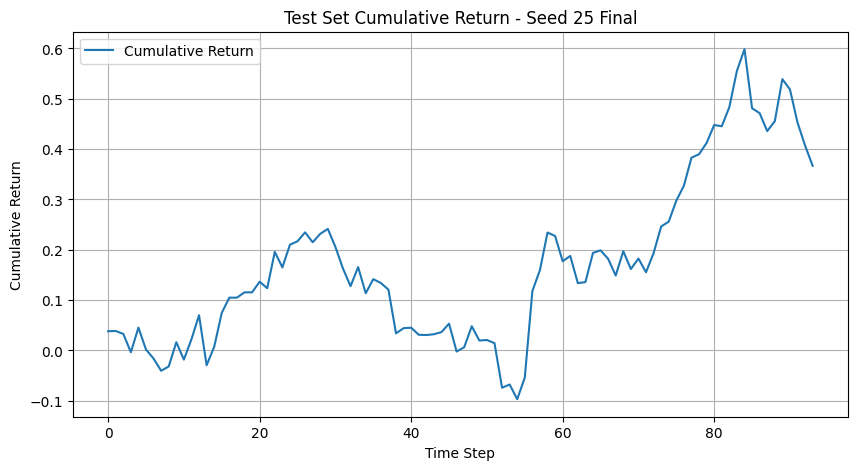

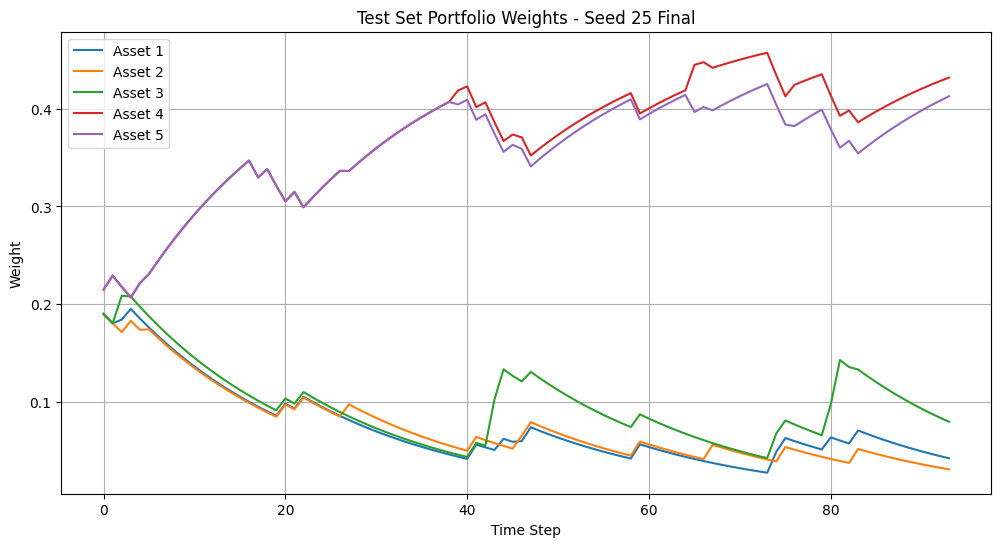

📊 Final Sharpe Ratio on Test Set: 1.4228


In [ ]:
# Path to the best model you saved
best_model_path = str(REPO_ROOT / "models" / "ppo_best_model_seed25_round10.zip")

# Run evaluation
test_returns_list, test_weights_array = evaluate_model_on_test(
    model_path=best_model_path,
    test_returns=test_returns,
    unnormalized_test_returns=unnormalized_returns.loc["2024-01-01":"2024-12-31"],  # Adjust test window
    seed=25
)

# Plot
plot_test_performance(test_returns_list, test_weights_array, seed_label="Seed 25 Final")
